# Análisis de resultados

Necesita los 5 archivos `metricas_*.csv` en `resultados/` (generados con `01_experimentos.ipynb`).
Las figuras se guardan en `figuras/` a 300 dpi, listas para el informe.

In [1]:
import analisis as A

r = A.cargar_resultados()
A.verificar_resultados(r)

OK: 5 modelos x 25 folds, mismas particiones para todos.


## Tabla principal
Media ± desviación estándar en los 25 folds. Rango medio en PR-AUC entre E1–E4 (1 = mejor).

In [2]:
A.tabla_resumen(r)

,PR-AUC,ROC-AUC,Recall top 5%,Precisión top 5%,Rango medio
E0 Dummy,0.035 ± 0.001,0.496 ± 0.012,0.037 ± 0.028,0.026 ± 0.019,—
E1 Reg. logística (base),0.168 ± 0.040,0.824 ± 0.031,0.266 ± 0.048,0.185 ± 0.033,1.60
E2 Árbol,0.104 ± 0.021,0.791 ± 0.027,0.171 ± 0.052,0.119 ± 0.036,3.92
E3 KNN,0.147 ± 0.025,0.827 ± 0.024,0.248 ± 0.049,0.173 ± 0.034,2.40
E4 XGBoost,0.151 ± 0.031,0.824 ± 0.026,0.251 ± 0.066,0.175 ± 0.046,2.08


## Pruebas estadísticas (PR-AUC)
Friedman → Nemenyi (todos los pares) y Wilcoxon pareado contra el caso base con corrección de Holm.

In [3]:
res = A.pruebas_estadisticas(r)
A.imprimir_pruebas(res)

Métrica: pr_auc  ·  25 folds
Friedman: chi2 = 45.192, p = 8.423e-10  -> hay diferencias

Rango medio (1 = mejor):
modelo
logreg     1.60
xgboost    2.08
knn        2.40
arbol      3.92

Diferencia crítica de Nemenyi (alfa = 0.05): 0.938
modelo_a modelo_b  dif_rango  significativo
  logreg  xgboost       0.48          False
  logreg      knn       0.80          False
  logreg    arbol       2.32           True
 xgboost      knn       0.32          False
 xgboost    arbol       1.84           True
     knn    arbol       1.52           True

Wilcoxon pareado contra el caso base (logreg), corrección de Holm:
 modelo  dif_media  p_wilcoxon  p_holm  significativo
  arbol    -0.0643      0.0000  0.0000           True
    knn    -0.0215      0.0006  0.0011           True
xgboost    -0.0167      0.0067  0.0067           True


Para repetir las pruebas con otra métrica: `A.pruebas_estadisticas(r, metrica="recall_top5")`.

## Figuras

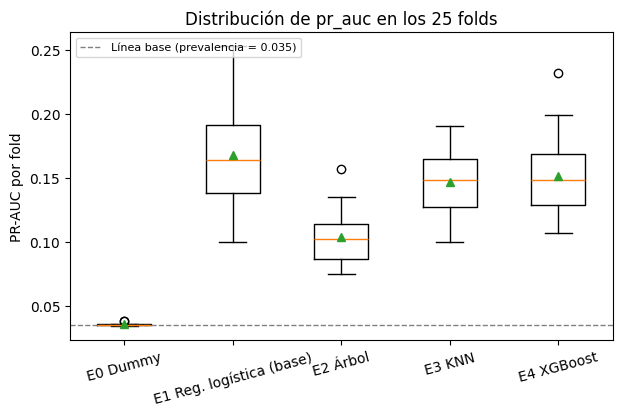

In [4]:
A.figura_boxplot(r);

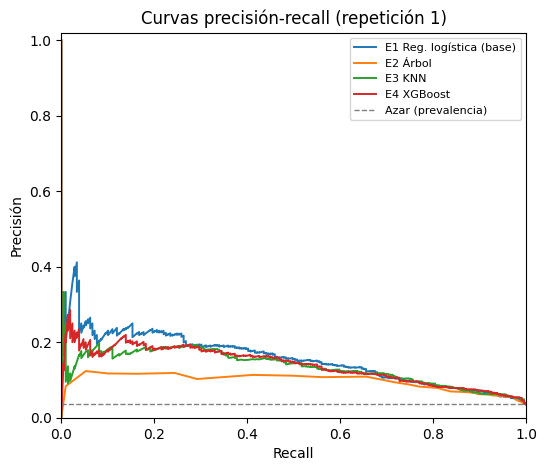

In [5]:
A.figura_curvas_pr();

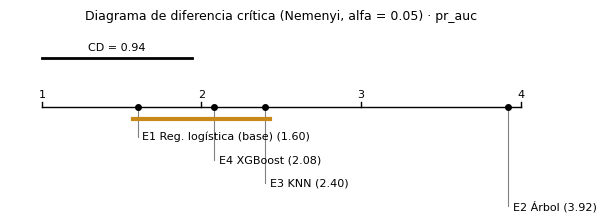

In [6]:
A.figura_cd(res);